# Module 7C — Matplotlib Foundations (เลือกเรียน)

ส่วนนี้มีไว้สำหรับผู้ที่ต้องการเปิดโค้ด ตรวจ และแก้ figure ด้วยตนเอง ไม่ใช่เงื่อนไขก่อนเรียน Part A–B
code cell ซ่อนเป็นค่าเริ่มต้น แต่เปิดดูได้ทีละ cell

เลขหน้าใน citation เป็นหน้า PDF ดูรายละเอียด tag และขอบเขตการสกัดที่
[source map](module-07-data-visualization-source-map.md)

## Setup แบบ standalone

เซลล์ถัดไปตรวจและติดตั้ง core package ของ Module 7 ให้ครบใน kernel ปัจจุบัน
ไม่อาศัย environment จาก Part A, Part B หรือบทก่อนหน้า

## 1. สามชั้นที่ควรรู้จัก

- **Backend:** ส่งภาพไปยังหน้าจอ ไฟล์ PNG/PDF/SVG หรือ notebook
- **Artist:** ทุกสิ่งที่มองเห็น เช่น line, text, legend, axis และ patch
- **Scripting interface:** `pyplot` ช่วยสร้าง Figure/Axes และเรียก Artist ได้สะดวก

สำหรับงานวิจัยให้ใช้ object-oriented style เป็นหลัก: สร้าง `fig, ax = plt.subplots()` แล้วเรียก
`ax.plot()`, `ax.set_xlabel()` และ `fig.savefig()` เพราะควบคุมหลาย panel และแก้เฉพาะ axes ได้ชัดกว่า

> **ที่มาหลัก:** `[DV-NOTES, pdf pp. 77–88]`; `[RT1-DATAVIZ, pdf pp. 38–40]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

Python: [current kernel]
Verified: {'numpy': '2.2.6', 'pandas': '2.3.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'plotly': '7.0.0', 'altair': '6.2.2'}


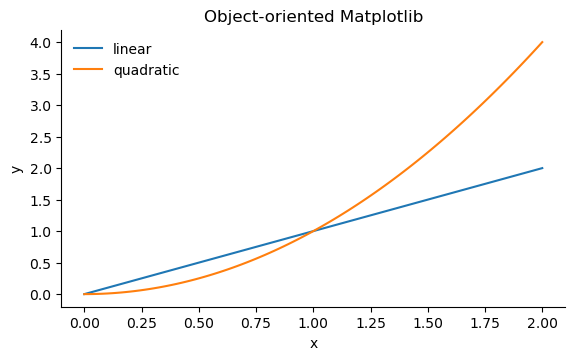

In [1]:
from importlib import invalidate_caches
from importlib.metadata import PackageNotFoundError, version
import subprocess
import sys

try:
    from packaging.specifiers import SpecifierSet
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "packaging>=24,<27"])
    invalidate_caches()
    from packaging.specifiers import SpecifierSet

required = {
    "numpy": ">=1.26,<3", "pandas": ">=2.1,<3", "matplotlib": ">=3.8,<4",
    "seaborn": ">=0.13,<0.14", "plotly": ">=5.20,<8", "altair": ">=5.2,<7",
}
to_install = []
for distribution, constraint in required.items():
    try:
        installed = version(distribution)
    except PackageNotFoundError:
        installed = None
    if installed is None or installed not in SpecifierSet(constraint):
        to_install.append(f"{distribution}{constraint}")
if to_install:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
        "--upgrade-strategy", "only-if-needed", *to_install,
    ])
    invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np

print("Python:", sys.executable)
print("Verified:", {name: version(name) for name in required})

x = np.linspace(0, 2, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(x, x, label="linear")
ax.plot(x, x**2, label="quadratic")
ax.set(xlabel="x", ylabel="y", title="Object-oriented Matplotlib")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Anatomy ของ figure

**Figure** คือพื้นที่ทั้งภาพ, **Axes** คือหนึ่ง plot พร้อมระบบพิกัด, **Axis** คือแกน x/y พร้อม tick และ label
และสิ่งที่วาดทั้งหมดเป็น Artist ตัวอย่างต่อไปติดป้ายส่วนสำคัญเพื่อให้ค้นตำแหน่งแก้กราฟได้

> **ที่มาหลัก:** `[DV-NOTES, pdf pp. 77–88]`; `[RT1-DATAVIZ, pdf p. 41]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

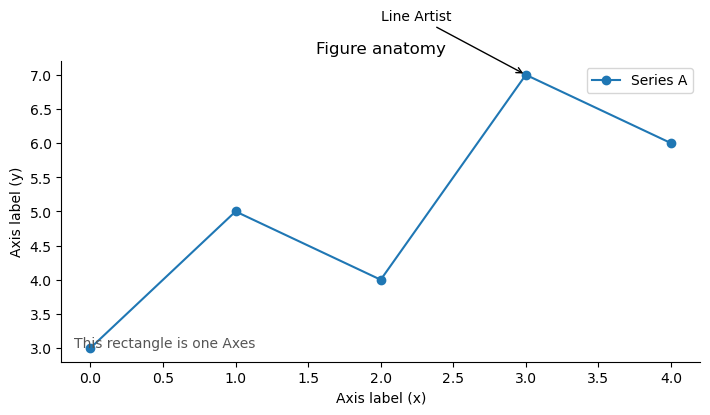

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 4.3))
x = np.arange(5); y = np.array([3, 5, 4, 7, 6])
line, = ax.plot(x, y, marker="o", label="Series A")
ax.set(title="Figure anatomy", xlabel="Axis label (x)", ylabel="Axis label (y)")
legend = ax.legend(frameon=True)
ax.annotate("Line Artist", xy=(3, 7), xytext=(2.0, 7.8), arrowprops={"arrowstyle":"->"})
ax.text(.02, .05, "This rectangle is one Axes", transform=ax.transAxes, color="#555")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 3. เมื่อใดต้องเปิดโค้ด

เปิดโค้ดเมื่อจำเป็นต้องตรวจ aggregation, เปลี่ยน scale/units, แก้ clipping, กำหนดขนาดจริง หรือส่งออกไฟล์
ไม่จำเป็นต้องเปิดเพียงเพื่อเปลี่ยนสีตามใจ หากยังอธิบาย Chart Contract และข้อค้นพบไม่ได้

> **ที่มาหลัก:** แนวทางบทเรียนสังเคราะห์จาก `[RT1-DATAVIZ, pdf pp. 38–50]` และ workflow ของ Module 7 ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน